In [1]:
from google.colab import files
uploaded = files.upload()

Saving Housing.csv to Housing.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Housing.csv')

print("Dataset Loaded Successfully!")
print(df.head())

Dataset Loaded Successfully!
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


In [3]:
print("Number of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Number of Rows and Columns:
(545, 13)

Column Names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  pr

In [4]:
print(df.describe())

              price          area    bedrooms   bathrooms     stories  \
count  5.450000e+02    545.000000  545.000000  545.000000  545.000000   
mean   4.766729e+06   5150.541284    2.965138    1.286239    1.805505   
std    1.870440e+06   2170.141023    0.738064    0.502470    0.867492   
min    1.750000e+06   1650.000000    1.000000    1.000000    1.000000   
25%    3.430000e+06   3600.000000    2.000000    1.000000    1.000000   
50%    4.340000e+06   4600.000000    3.000000    1.000000    2.000000   
75%    5.740000e+06   6360.000000    3.000000    2.000000    2.000000   
max    1.330000e+07  16200.000000    6.000000    4.000000    4.000000   

          parking  
count  545.000000  
mean     0.693578  
std      0.861586  
min      0.000000  
25%      0.000000  
50%      0.000000  
75%      1.000000  
max      3.000000  


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Records:
0


In [6]:
# Remove duplicate records
df = df.drop_duplicates()

# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:")
print(df.shape)

Missing Values After Cleaning:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Dataset Shape After Cleaning:
(545, 13)


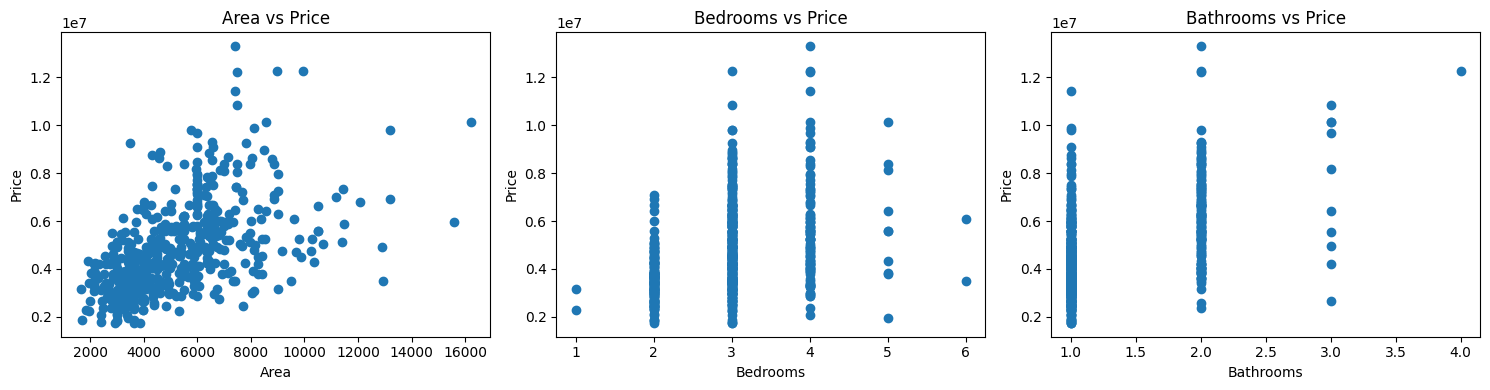

In [7]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(df['area'], df['price'])
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Area vs Price')

plt.subplot(1, 3, 2)
plt.scatter(df['bedrooms'], df['price'])
plt.xlabel('Bedrooms')
plt.ylabel('Price')
plt.title('Bedrooms vs Price')

plt.subplot(1, 3, 3)
plt.scatter(df['bathrooms'], df['price'])
plt.xlabel('Bathrooms')
plt.ylabel('Price')
plt.title('Bathrooms vs Price')

plt.tight_layout()
plt.show()

In [8]:
corr = df.select_dtypes(include=np.number).corr()

print(corr)

              price      area  bedrooms  bathrooms   stories   parking
price      1.000000  0.535997  0.366494   0.517545  0.420712  0.384394
area       0.535997  1.000000  0.151858   0.193820  0.083996  0.352980
bedrooms   0.366494  0.151858  1.000000   0.373930  0.408564  0.139270
bathrooms  0.517545  0.193820  0.373930   1.000000  0.326165  0.177496
stories    0.420712  0.083996  0.408564   0.326165  1.000000  0.045547
parking    0.384394  0.352980  0.139270   0.177496  0.045547  1.000000


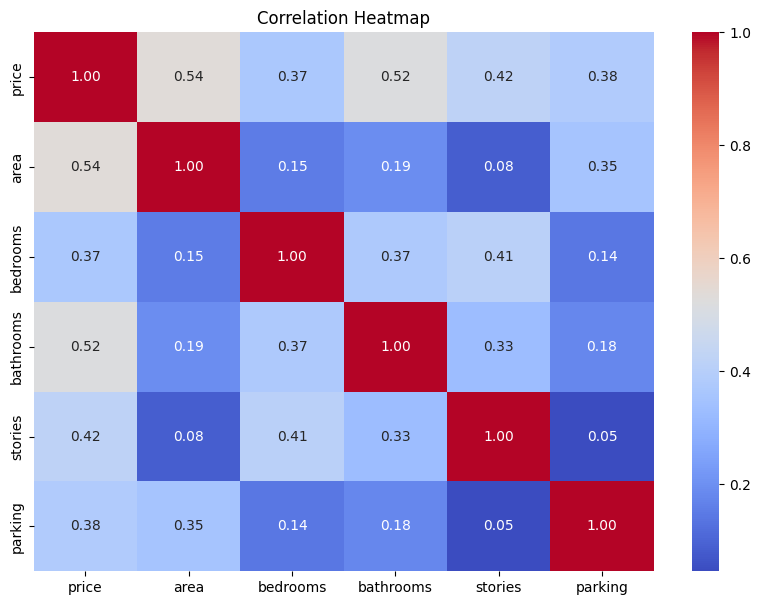

In [9]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [10]:
print("Correlation with House Price:")

print(corr['price'].sort_values(ascending=False))

Correlation with House Price:
price        1.000000
area         0.535997
bathrooms    0.517545
stories      0.420712
parking      0.384394
bedrooms     0.366494
Name: price, dtype: float64


In [11]:
sample = df[['area', 'bedrooms', 'price']].head(5)

print("Selected 5 Observations:")
print(sample.to_string(index=False))

Selected 5 Observations:
 area  bedrooms    price
 7420         4 13300000
 8960         4 12250000
 9960         3 12250000
 7500         4 12215000
 7420         4 11410000


In [12]:
import numpy as np

X = np.column_stack((
    np.ones(len(sample)),
    sample['area'],
    sample['bedrooms']
))

Y = sample['price'].to_numpy()

print("Design Matrix X:")
print(X)

print("\nTarget Matrix Y:")
print(Y)

Design Matrix X:
[[1.00e+00 7.42e+03 4.00e+00]
 [1.00e+00 8.96e+03 4.00e+00]
 [1.00e+00 9.96e+03 3.00e+00]
 [1.00e+00 7.50e+03 4.00e+00]
 [1.00e+00 7.42e+03 4.00e+00]]

Target Matrix Y:
[13300000 12250000 12250000 12215000 11410000]


In [13]:
XT = X.T

XTX = XT @ X

print("Transpose of X:")
print(XT)

print("\nX Transpose multiplied by X:")
print(XTX)

Transpose of X:
[[1.00e+00 1.00e+00 1.00e+00 1.00e+00 1.00e+00]
 [7.42e+03 8.96e+03 9.96e+03 7.50e+03 7.42e+03]
 [4.00e+00 4.00e+00 3.00e+00 4.00e+00 4.00e+00]]

X Transpose multiplied by X:
[[5.00000e+00 4.12600e+04 1.90000e+01]
 [4.12600e+04 3.45846e+08 1.55080e+05]
 [1.90000e+01 1.55080e+05 7.30000e+01]]


In [14]:
XTY = XT @ Y

print("X Transpose multiplied by Y:")
print(XTY)

X Transpose multiplied by Y:
[6.142500e+07 5.067307e+11 2.334500e+08]


In [15]:
B = np.linalg.solve(XTX, XTY)

b0, b1, b2 = B

print("Intercept:", b0)
print("Area Coefficient:", b1)
print("Bedroom Coefficient:", b2)

print("\nRegression Equation:")
print(f"Price = {b0:.4f} + {b1:.4f}(Area) + {b2:.4f}(Bedrooms)")

Intercept: 12818959.86991
Area Coefficient: -42.78703757470951
Bedroom Coefficient: -47600.325221973006

Regression Equation:
Price = 12818959.8699 + -42.7870(Area) + -47600.3252(Bedrooms)


In [16]:
predicted = X @ B

residual = Y - predicted

print("Actual Price:", Y[0])
print("Predicted Price:", predicted[0])
print("Residual:", residual[0])

Actual Price: 13300000
Predicted Price: 12311078.750217764
Residual: 988921.2497822363


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [18]:
# Simple Linear Regression
X_simple = df[['area']]
y = df['price']

# Multiple Linear Regression
X_multiple = df[['area', 'bedrooms', 'bathrooms']]

print("Simple Input:")
print(X_simple.head())

print("\nMultiple Input:")
print(X_multiple.head())

print("\nTarget:")
print(y.head())

Simple Input:
   area
0  7420
1  8960
2  9960
3  7500
4  7420

Multiple Input:
   area  bedrooms  bathrooms
0  7420         4          2
1  8960         4          4
2  9960         3          2
3  7500         4          2
4  7420         4          1

Target:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64


In [19]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

print("Simple Regression Training:", X_train_s.shape)
print("Simple Regression Testing:", X_test_s.shape)

print("Multiple Regression Training:", X_train_m.shape)
print("Multiple Regression Testing:", X_test_m.shape)

Simple Regression Training: (436, 1)
Simple Regression Testing: (109, 1)
Multiple Regression Training: (436, 3)
Multiple Regression Testing: (109, 3)


In [20]:
simple_model = LinearRegression()

simple_model.fit(X_train_s, y_train_s)

print("Simple Linear Regression Trained!")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_)

Simple Linear Regression Trained!
Intercept: 2512254.2639593435
Coefficient: [425.72984194]


In [21]:
simple_model = LinearRegression()

simple_model.fit(X_train_s, y_train_s)

print("Simple Linear Regression Trained!")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_)

Simple Linear Regression Trained!
Intercept: 2512254.2639593435
Coefficient: [425.72984194]


In [22]:
multiple_model = LinearRegression()

multiple_model.fit(X_train_m, y_train_m)

print("Multiple Linear Regression Trained!")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)

Multiple Linear Regression Trained!
Intercept: 59485.379208717495
Coefficients: [3.45466570e+02 3.60197650e+05 1.42231966e+06]


In [23]:
print("Simple Linear Regression Equation:")

print(
    f"Price = {simple_model.intercept_:.2f} "
    f"+ {simple_model.coef_[0]:.2f} * Area"
)

print("\nMultiple Linear Regression Equation:")

print(
    f"Price = {multiple_model.intercept_:.2f} "
    f"+ {multiple_model.coef_[0]:.2f} * Area"
    f" + {multiple_model.coef_[1]:.2f} * Bedrooms"
    f" + {multiple_model.coef_[2]:.2f} * Bathrooms"
)

Simple Linear Regression Equation:
Price = 2512254.26 + 425.73 * Area

Multiple Linear Regression Equation:
Price = 59485.38 + 345.47 * Area + 360197.65 * Bedrooms + 1422319.66 * Bathrooms


In [24]:
print("Multiple Regression Intercept:", multiple_model.intercept_)

print("\nFeature Coefficients:")
for feature, coef in zip(X_multiple.columns, multiple_model.coef_):
    print(f"{feature}: {coef:.2f}")

Multiple Regression Intercept: 59485.379208717495

Feature Coefficients:
area: 345.47
bedrooms: 360197.65
bathrooms: 1422319.66


In [25]:
y_pred = multiple_model.predict(X_test_m)

print("Actual House Prices:")
print(y_test_m.head(10).values)

print("\nPredicted House Prices:")
print(y_pred[:10])

Actual House Prices:
[4060000 6650000 3710000 6440000 2800000 4900000 5250000 4543000 2450000
 3353000]

Predicted House Prices:
[6383168.05981192 6230250.35140428 3597885.28090091 4289730.8386382
 3930445.60575177 4883933.33918115 5505773.16533075 6068793.48103629
 3321512.02483442 3495157.72744705]


In [26]:
comparison = pd.DataFrame({
    'Actual Price': y_test_m.values,
    'Predicted Price': y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0       4060000     6.383168e+06
1       6650000     6.230250e+06
2       3710000     3.597885e+06
3       6440000     4.289731e+06
4       2800000     3.930446e+06
5       4900000     4.883933e+06
6       5250000     5.505773e+06
7       4543000     6.068793e+06
8       2450000     3.321512e+06
9       3353000     3.495158e+06


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test_m, y_pred)
mse = mean_squared_error(y_test_m, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_m, y_pred)

print("Model Performance:")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Performance:
MAE: 1265275.6699454375
MSE: 2750040479309.0522
RMSE: 1658324.6001036866
R2 Score: 0.4559299118872445


In [28]:
# Predictions from Simple Linear Regression
y_pred_simple = simple_model.predict(X_test_s)

# Predictions from Multiple Linear Regression
y_pred_multiple = multiple_model.predict(X_test_m)

# Calculate performance metrics
results = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'MAE': [
        mean_absolute_error(y_test_s, y_pred_simple),
        mean_absolute_error(y_test_m, y_pred_multiple)
    ],
    'MSE': [
        mean_squared_error(y_test_s, y_pred_simple),
        mean_squared_error(y_test_m, y_pred_multiple)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test_s, y_pred_simple)),
        np.sqrt(mean_squared_error(y_test_m, y_pred_multiple))
    ],
    'R2 Score': [
        r2_score(y_test_s, y_pred_simple),
        r2_score(y_test_m, y_pred_multiple)
    ]
})

print(results)

                        Model           MAE           MSE          RMSE  \
0    Simple Linear Regression  1.474748e+06  3.675287e+12  1.917104e+06   
1  Multiple Linear Regression  1.265276e+06  2.750040e+12  1.658325e+06   

   R2 Score  
0  0.272879  
1  0.455930  


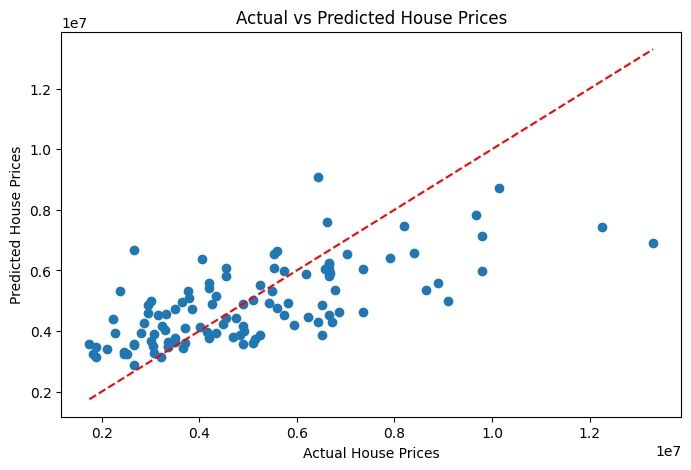

In [29]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test_m, y_pred_multiple)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

# Perfect prediction reference line
min_value = min(y_test_m.min(), y_pred_multiple.min())
max_value = max(y_test_m.max(), y_pred_multiple.max())

plt.plot([min_value, max_value],
         [min_value, max_value],
         'r--')

plt.show()

## Conclusion

In this activity, I implemented Multiple Linear Regression using the House Price Prediction dataset.

I selected Area, Bedrooms and Bathrooms as independent variables and Price as the dependent variable.

I performed data loading, inspection, cleaning, visualization and model training. I also implemented Simple Linear Regression and Multiple Linear Regression.

The models were evaluated using MAE, MSE, RMSE and R² score. The Actual vs Predicted graph helped visualize the prediction performance.

Thus, I learned how Multiple Linear Regression predicts house prices using multiple input features.